[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arielzamora/tpi-analisis-de-datos/blob/main/notebooks/TPI_Analisis_de_Datos.ipynb)

# 📊 Trabajo Práctico: Análisis de Datos
## **Materia:** Ciencia de Datos / Análisis de Datos
### **Profesor:** Zotti, Enzo Martín

---

## 👥 **Grupo N° 8**
### **Integrantes:**
* 👤 **Toledo**, Luanda
* 👤 **Medina**, Gisele
* 👤 **Bianucci**, Juan Cruz
* 👤 **Zamora**, Ariel

---

## 📑 **Dataset Principal: Telco Customer Churn**
* **Fuente:** Kaggle
* **Descripción:** Registro histórico de clientes de un servicio de telecomunicaciones. Integra variables sociodemográficas, características de contratación, desglose de facturación y el estado de cancelación de la suscripción (`Churn`).

### 🎯 **Objetivos del Análisis**

Una empresa de telecomunicaciones quiere identificar qué características se relacionan con la cancelación de sus clientes y utilizar los datos históricos para mejorar sus estrategias de retención.

1. **Identificar patrones:** Determinar qué perfil de cliente es más propenso a cancelar el servicio.
2. **Análisis de características:** Evaluar el impacto de los tipos de contrato y servicios adicionales en la retención.
3. **Optimización financiera:** Analizar la facturación mensual y total para detectar puntos críticos de fuga de ingresos.

---



## Organización del notebook

Este cuaderno desarrolla
- **Parte A: Fundamentos, Ingesta, Limpieza y Manipulación de Datos**. Se conserva el dataset original en `df` y se trabaja sobre una copia limpia llamada `df_clean`.

- **Parte B: Análisis Exploratorio, Visualización e Integración.** Análisis Exploratorio de Datos y Estadística Aplicada.Análisis Cuantitativo.Análisis Categórico.Visualización de Datos.

- **Parte C: Preprocesamiento y Modelado Predictivo.** Preprocesamiento de Datos para Modelado. Predicción Numérica: Modelos de Regresión. Predicción Categórica: Modelos de Clasificación.



In [55]:
#################################
## UTILS: VARIBLES Y FUNCIONES ##
#################################

from IPython.display import display, HTML

# color_primario = "#D97706"
# color_secundario = "#0f172a"
# color_terciario = "#64748b"


# Opc. C: Cyberpunk Bumblebee
color_primario = "#EAB308"
color_secundario = "#334155"
color_terciario = "#475569"

def mostrar_titulo(texto):
    """Muestra un título elegante con una línea separadora color primario"""
    diseño = f"""
    <div style="border-bottom: 2px solid {color_primario}; padding-bottom: 5px; margin-top: 20px; margin-bottom: 10px;">
        <h2 style="color: {color_primario}; font-family: sans-serif; margin: 0;">📌 {texto}</h2>
    </div>
    """
    display(HTML(diseño))

def resaltar_dato(etiqueta, valor, color=color_secundario):
    """Muestra una variable o dato importante resaltado dentro de un recuadro limpio."""
    diseño = f"""
    <div style="font-family: sans-serif; margin: 5px 0; padding: 10px; border-left: 5px solid {color}; background-color: #f8f9fa; border-radius: 4px;">
        <span style="font-weight: bold; color: #555;">{etiqueta}:</span>
        <span style="font-weight: bold; color: {color}; font-size: 1.1em;">{valor}</span>
    </div>
    """
    display(HTML(diseño))


## Importación de bibliotecas

In [56]:
# librerias basicas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Estilo gráfico estandarizado
sns.set_theme(style="darkgrid");
plt.rcParams["figure.figsize"] = (10, 6)

# librerias para el punto  de Preprocesamiento y Modelado predictivo
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import r2_score, mean_absolute_error, accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# A. Fundamentos, Ingesta y Limpieza de Datos

## 1. Problema de negocio, objetivo e hipótesis

**Problema de negocio:** una empresa de telecomunicaciones pierde clientes cuando estos cancelan su servicio (*Customer Churn*). Comprender qué características se relacionan con el abandono puede ayudar a orientar futuras estrategias de retención.

**Objetivo:** identificar características de los clientes asociadas con el abandono del servicio.

**Hipótesis:** los clientes con contratos mensuales presentan una tasa de abandono mayor que los clientes con contratos de uno o dos años.

**Variable objetivo:** `Churn`, que indica si el cliente abandonó (`Yes`) o continuó (`No`) con el servicio.

## 2. Carga e inspección inicial

El dataset es **estructurado** porque organiza cada cliente en una fila y sus características en columnas. Primero se inspecciona el archivo original antes de realizar modificaciones.

In [57]:
# Cargar el dataset original
#path_csv = "/content/WA_Fn-UseC_-Telco-Customer-Churn.csv"

# Cargar el dataset original directamente desde GitHub (reproducible en Colab)
path_csv = "https://raw.githubusercontent.com/arielzamora/tpi-analisis-de-datos/refs/heads/main/data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv"
df = pd.read_csv(path_csv)


mostrar_titulo("Primeras filas del dataset")
display(df.head())

mostrar_titulo("Dimensiones del dataset")
resaltar_dato("Cantidad de registros", f"{df.shape[0]:,} filas", color=color_primario)
resaltar_dato("Cantidad de variables", f"{df.shape[1]} columnas", color=color_secundario)

mostrar_titulo("Nombres y tipos de datos originales")
display(df.dtypes.rename("dtype de Pandas").to_frame())

mostrar_titulo("Resumen de valores nulos .info()");
# Captura la info
info_df = pd.DataFrame({
    'Tipo de Dato': df.dtypes,
    'Valores No Nulos': df.notnull().sum(),
    'Valores Nulos': df.isnull().sum(),
    'Porcentaje Nulos (%)': (df.isnull().mean() * 100).round(2)
})

display(info_df)



,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


,dtype de Pandas
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


,Tipo de Dato,Valores No Nulos,Valores Nulos,Porcentaje Nulos (%)
customerID,object,7043,0,0.0
gender,object,7043,0,0.0
SeniorCitizen,int64,7043,0,0.0
Partner,object,7043,0,0.0
Dependents,object,7043,0,0.0
tenure,int64,7043,0,0.0
PhoneService,object,7043,0,0.0
MultipleLines,object,7043,0,0.0
InternetService,object,7043,0,0.0
OnlineSecurity,object,7043,0,0.0


## 3. Clasificación teórica de las variables

La clasificación estadística describe qué representa cada variable; `dtypes` indica cómo está almacenada en Pandas. Por eso, una variable numérica como `SeniorCitizen` puede representar una categoría binaria, aunque inicialmente se almacene como entero.

In [58]:
mostrar_titulo("Relevamiento del tipo de variables ")

clasificacion_teorica = {
    'customerID': 'Cualitativa nominal (identificador)',
    'gender': 'Cualitativa nominal',
    'SeniorCitizen': 'Cualitativa nominal binaria (codificada 0/1)',
    'Partner': 'Cualitativa nominal binaria',
    'Dependents': 'Cualitativa nominal binaria',
    'tenure': 'Cuantitativa discreta (meses)',
    'PhoneService': 'Cualitativa nominal binaria',
    'MultipleLines': 'Cualitativa nominal',
    'InternetService': 'Cualitativa nominal',
    'OnlineSecurity': 'Cualitativa nominal',
    'OnlineBackup': 'Cualitativa nominal',
    'DeviceProtection': 'Cualitativa nominal',
    'TechSupport': 'Cualitativa nominal',
    'StreamingTV': 'Cualitativa nominal',
    'StreamingMovies': 'Cualitativa nominal',
    'Contract': 'Cualitativa ordinal (duración del contrato)',
    'PaperlessBilling': 'Cualitativa nominal binaria',
    'PaymentMethod': 'Cualitativa nominal',
    'MonthlyCharges': 'Cuantitativa continua',
    'TotalCharges': 'Cuantitativa continua',
    'Churn': 'Cualitativa nominal binaria (variable objetivo)'
}

tabla_variables = pd.DataFrame({
    'Clasificación teórica': pd.Series(clasificacion_teorica),
    'dtype original en Pandas': df.dtypes.astype(str),
    'Ejemplo de valor': df.iloc[0].astype(str)
})
tabla_variables.index.name = 'Variable'
display(tabla_variables.reset_index())

# En TotalCharges, algunos espacios aparecen como texto y deben detectarse aparte.
vacios_totalcharges = df['TotalCharges'].astype('string').str.strip().eq('').sum()
resaltar_dato("Espacios vacíos detectados en TotalCharges", f"{vacios_totalcharges}", color=color_secundario)

,Variable,Clasificación teórica,dtype original en Pandas,Ejemplo de valor
0,customerID,Cualitativa nominal (identificador),object,7590-VHVEG
1,gender,Cualitativa nominal,object,Female
2,SeniorCitizen,Cualitativa nominal binaria (codificada 0/1),int64,0
3,Partner,Cualitativa nominal binaria,object,Yes
4,Dependents,Cualitativa nominal binaria,object,No
5,tenure,Cuantitativa discreta (meses),int64,1
6,PhoneService,Cualitativa nominal binaria,object,No
7,MultipleLines,Cualitativa nominal,object,No phone service
8,InternetService,Cualitativa nominal,object,DSL
9,OnlineSecurity,Cualitativa nominal,object,No


## 4. Limpieza y control de calidad

Se crea una copia para conservar el dataset original. Se controlan duplicados, se convierten los espacios vacíos de `TotalCharges` en valores nulos reales, se transforma la columna a numérica y se tratan los 11 casos faltantes.

**Decisión de imputación:** los 11 registros presentan `tenure = 0` y `Churn = No`. Se reemplazan los valores faltantes de `TotalCharges` por `0`, interpretándolos como clientes sin cargos acumulados registrados. Es una decisión basada en el contexto disponible, no una certeza sobre la facturación real, por lo que se deja documentada.

In [59]:
# Copia de trabajo para no modificar el dataset original

df_clean = df.copy();

# 1. Control de duplicados
mostrar_titulo("Control de duplicados");

duplicados = int(df_clean.duplicated().sum())
resaltar_dato("Filas duplicadas detectadas", duplicados, color=color_primario)

if duplicados > 0:
    df_clean = df_clean.drop_duplicates().copy()
    print(f"Se eliminaron {duplicados} filas duplicadas.\n")
else:
    print("No se encontraron filas duplicadas.\n")


# 2. Limpiar espacios en blanco y convertir TotalCharges a numérico
mostrar_titulo("Limpieza y control de calidad de TotalCharges");

df_clean['TotalCharges'] = df_clean['TotalCharges'].replace(r'^\s*$', np.nan, regex=True)
df_clean['TotalCharges'] = pd.to_numeric(df_clean['TotalCharges'], errors='coerce')

nulos_totalcharges = int(df_clean['TotalCharges'].isna().sum())
resaltar_dato("Valores faltantes en TotalCharges antes de imputar", nulos_totalcharges, color=color_secundario)

# Mostrar los registros faltantes para comprobar el contexto
df_con_faltantes=df_clean.loc[df_clean['TotalCharges'].isna(), ['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']];
if nulos_totalcharges > 0:
    display(df_con_faltantes.head());

# Imputación fundamentada: los casos detectados tienen tenure = 0 y Churn = No.
df_clean['TotalCharges'] = df_clean['TotalCharges'].fillna(0)
resaltar_dato("Imputación de nulos en TotalCharges con ",0,color_primario);

mostrar_titulo("Limpieza y control de calidad de variables categoricas")
# 3. Convertir SeniorCitizen de 0/1 a categorías legibles
df_clean['SeniorCitizen'] = df_clean['SeniorCitizen'].map({1: 'yes', 0: 'no'})

# 4. Quitar espacios y unificar a minúsculas las variables de texto,
# excepto el identificador, cuyo contenido se conserva.
columnas_texto = df_clean.select_dtypes(include=['object']).columns
for col in columnas_texto:
    if col != 'customerID':
        df_clean[col] = df_clean[col].astype('string').str.strip().str.lower()

# Convertir las columnas categóricas a dtype category, excepto el identificador
columnas_categoricas = [
    col for col in df_clean.select_dtypes(include=['object', 'string']).columns
    if col != 'customerID'
]
for col in columnas_categoricas:
    df_clean[col] = df_clean[col].astype('category')

display(df_clean.select_dtypes(include=['object','category', 'string']).head());


mostrar_titulo("Resumen de calidad después de la limpieza y adecuación de tipos de datos")
reporte_calidad = pd.DataFrame({
    'dtype': df_clean.dtypes.astype(str),
    'valores_nulos': df_clean.isna().sum(),
    'porcentaje_nulos': (df_clean.isna().mean() * 100).round(2)
})
display(reporte_calidad)

resaltar_dato("Cantidad de registros limpios", f"{df_clean.shape[0]:,} filas", color=color_primario)
resaltar_dato("Cantidad de variables ", f"{df_clean.shape[1]} columnas", color=color_secundario)

mostrar_titulo("Primeras filas del dataset limpio");
display(df_clean.head())

No se encontraron filas duplicadas.



,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,NaN,No
753,0,20.25,NaN,No
936,0,80.85,NaN,No
1082,0,25.75,NaN,No
1340,0,56.05,NaN,No


,customerID,gender,SeniorCitizen,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,Churn
0,7590-VHVEG,female,no,yes,no,no,no phone service,dsl,no,yes,no,no,no,no,month-to-month,yes,electronic check,no
1,5575-GNVDE,male,no,no,no,yes,no,dsl,yes,no,yes,no,no,no,one year,no,mailed check,no
2,3668-QPYBK,male,no,no,no,yes,no,dsl,yes,yes,no,no,no,no,month-to-month,yes,mailed check,yes
3,7795-CFOCW,male,no,no,no,no,no phone service,dsl,yes,no,yes,yes,no,no,one year,no,bank transfer (automatic),no
4,9237-HQITU,female,no,no,no,yes,no,fiber optic,no,no,no,no,no,no,month-to-month,yes,electronic check,yes


,dtype,valores_nulos,porcentaje_nulos
customerID,object,0,0.0
gender,category,0,0.0
SeniorCitizen,category,0,0.0
Partner,category,0,0.0
Dependents,category,0,0.0
tenure,int64,0,0.0
PhoneService,category,0,0.0
MultipleLines,category,0,0.0
InternetService,category,0,0.0
OnlineSecurity,category,0,0.0


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,female,no,yes,no,1,no,no phone service,dsl,no,...,no,no,no,no,month-to-month,yes,electronic check,29.85,29.85,no
1,5575-GNVDE,male,no,no,no,34,yes,no,dsl,yes,...,yes,no,no,no,one year,no,mailed check,56.95,1889.50,no
2,3668-QPYBK,male,no,no,no,2,yes,no,dsl,yes,...,no,no,no,no,month-to-month,yes,mailed check,53.85,108.15,yes
3,7795-CFOCW,male,no,no,no,45,no,no phone service,dsl,yes,...,yes,yes,no,no,one year,no,bank transfer (automatic),42.30,1840.75,no
4,9237-HQITU,female,no,no,no,2,yes,no,fiber optic,no,...,no,no,no,no,month-to-month,yes,electronic check,70.70,151.65,yes


## 5. Identificación de valores atípicos (IQR)

Se aplica el rango intercuartílico (IQR) a `tenure`, `MonthlyCharges` y `TotalCharges`. Los valores fuera de los límites se consideran **posibles** valores atípicos, no errores automáticamente. Se conservan los registros y se documenta el resultado, porque los valores altos pueden representar situaciones reales de contratación o facturación.

,variable,Q1,Q3,IQR,limite_inferior,limite_superior,posibles_outliers
0,tenure,9.00,55.00,46.00,-60.00,124.00,0
1,MonthlyCharges,35.50,89.85,54.35,-46.02,171.38,0
2,TotalCharges,398.55,3786.60,3388.05,-4683.52,8868.67,0


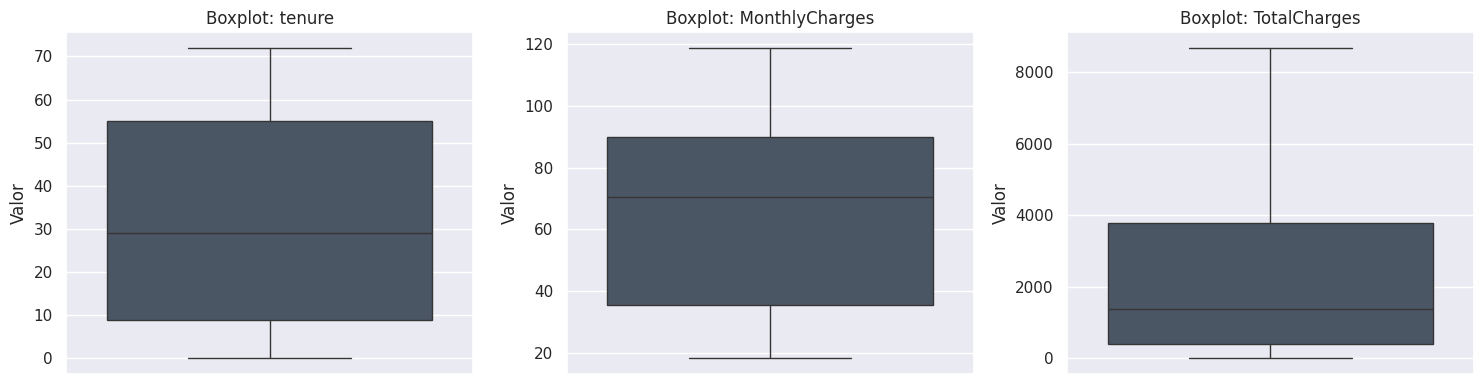

Tratamiento: se conservan los registros; el criterio IQR identifica valores extremos, pero no demuestra por sí solo que sean errores.


In [60]:
mostrar_titulo("Detección y verificación de Outliers mediante IQR");

variables_numericas = ['tenure', 'MonthlyCharges', 'TotalCharges']
resultados_iqr = []

for col in variables_numericas:
    datos = df_clean[col].dropna()
    q1 = datos.quantile(0.25)
    q3 = datos.quantile(0.75)
    iqr = q3 - q1
    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr
    cantidad_outliers = int(((datos < limite_inferior) | (datos > limite_superior)).sum())

    resultados_iqr.append({
        'variable': col,
        'Q1': q1,
        'Q3': q3,
        'IQR': iqr,
        'limite_inferior': limite_inferior,
        'limite_superior': limite_superior,
        'posibles_outliers': cantidad_outliers
    })

tabla_iqr = pd.DataFrame(resultados_iqr)
display(tabla_iqr.round(2))

mostrar_titulo("Representación Gráfica mediante Diagramas de Caja (Boxplots)");
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, variables_numericas):
    sns.boxplot(data=df_clean, y=col, ax=ax,color=color_terciario)
    ax.set_title(f'Boxplot: {col}')
    ax.set_ylabel('Valor')
plt.tight_layout()
plt.show()

print("Tratamiento: se conservan los registros; el criterio IQR identifica valores extremos, pero no demuestra por sí solo que sean errores.")

## 6. Manipulación y segmentación con Pandas

Los filtros de esta sección son ejemplos de selección de registros. El primer filtro se vincula directamente con la hipótesis: selecciona clientes con contrato mensual que abandonaron el servicio.

In [61]:
# Estandarizar los nombres de columnas una sola vez.
# Los valores categóricos ya están en minúsculas desde la limpieza.
df_manipulacion=df_clean.copy();
df_manipulacion.columns = df_manipulacion.columns.str.lower()

mostrar_titulo("Filtrado (operadores & y | )")
# Filtro AND (&): clientes con contrato mensual que abandonaron
clientes_mensuales_que_abandonaron = df_manipulacion[
    (df_manipulacion['contract'] == 'month-to-month') &
    (df_manipulacion['churn'] == 'yes')
].copy()

resaltar_dato(
    "Filtro lógico AND",
    f"Clientes con contrato mensual que abandonaron {len(clientes_mensuales_que_abandonaron)} clientes",
    color=color_secundario
)

# Filtro OR (|): clientes con cargos acumulados altos O antigüedad superior a 60 meses
clientes_cargos_o_antiguedad_altos = df_manipulacion[
    (df_manipulacion['totalcharges'] > 5000) |
    (df_manipulacion['tenure'] > 60)
].copy()

resaltar_dato(
    "Filtro lógico OR",
    f"{len(clientes_cargos_o_antiguedad_altos)} clientes con TotalCharges > 5000 o tenure > 60 meses",
    color=color_primario
)
mostrar_titulo("Agregacion multidimensional por Tipo de contrato y Estado de abandono ")
# Agregación múltiple por tipo de contrato y estado de abandono
resumen_segmentos = df_manipulacion.groupby(['contract', 'churn'], observed=True).agg(
    cantidad_clientes=('churn', 'size'),
    antiguedad_promedio=('tenure', 'mean'),
    cargo_mensual_promedio=('monthlycharges', 'mean'),
    facturacion_acumulada=('totalcharges', 'sum')
).reset_index();
display(resumen_segmentos.round(2))

mostrar_titulo("Rename de algunas columnas ")
#  Renombrar columnas a nombres descriptivos en español
df_transformado = df_manipulacion.rename(columns={
    'tenure': 'antiguedad_meses',
    'monthlycharges': 'cargo_mensual',
    'totalcharges': 'total_facturado',
    'paymentmethod': 'metodo_pago',
    'contract': 'tipo_contrato',
    'churn': 'abandono'
}).copy()
resaltar_dato("ANTES ",df_manipulacion.columns.tolist(), color=color_secundario);
resaltar_dato("DESPUES ",df_transformado.columns.tolist(), color=color_terciario);

mostrar_titulo("\nCreacion de columna servicios_contratatados");
# Contar cuántos de los seis servicios indicados tiene cada cliente.
columnas_servicios = [
    'onlinesecurity', 'onlinebackup', 'deviceprotection',
    'techsupport', 'streamingtv', 'streamingmovies'
]
df_transformado['servicios_contratados'] = (
    df_manipulacion[columnas_servicios].eq('yes').sum(axis=1)
)
display(df_transformado[[
    'onlinesecurity', 'onlinebackup', 'deviceprotection',
    'techsupport', 'streamingtv', 'streamingmovies','servicios_contratados'
]].head());

mostrar_titulo("Drop sobre el identificador customerId ")
# El identificador no aporta información analítica directa; se elimina
# solamente del DataFrame derivado, no de df_clean.
df_procesado = df_transformado.copy();
df_procesado = df_procesado.drop(columns=['customerid']);
resaltar_dato("Columnas restantes ",df_procesado.columns.tolist(), color=color_terciario);


mostrar_titulo("Vista previa de los datos transformados")
display(df_procesado[
    ['antiguedad_meses', 'cargo_mensual', 'total_facturado',
     'servicios_contratados', 'tipo_contrato', 'abandono']
].head())

# Tabla para evaluar la hipótesis mediante tasas, no solo cantidades.
tasa_abandono_contrato = df_procesado.groupby('tipo_contrato', observed=True).agg(
    cantidad_clientes=('abandono', 'size'),
    clientes_que_abandonaron=('abandono', lambda serie: (serie == 'yes').sum()),
    tasa_abandono_pct=('abandono', lambda serie: (serie == 'yes').mean() * 100)
).reset_index()

display(tasa_abandono_contrato.round(2))

,contract,churn,cantidad_clientes,antiguedad_promedio,cargo_mensual_promedio,facturacion_acumulada
0,month-to-month,no,2220,21.03,61.46,3378679.25
1,month-to-month,yes,1655,14.02,73.02,1927182.25
2,one year,no,1307,41.67,62.51,3792062.30
3,one year,yes,166,44.96,85.05,674991.20
4,two year,no,1647,56.60,60.01,6022500.25
5,two year,yes,48,61.27,86.78,260753.45


,onlinesecurity,onlinebackup,deviceprotection,techsupport,streamingtv,streamingmovies,servicios_contratados
0,no,yes,no,no,no,no,1
1,yes,no,yes,no,no,no,2
2,yes,yes,no,no,no,no,2
3,yes,no,yes,yes,no,no,3
4,no,no,no,no,no,no,0


,antiguedad_meses,cargo_mensual,total_facturado,servicios_contratados,tipo_contrato,abandono
0,1,29.85,29.85,1,month-to-month,no
1,34,56.95,1889.50,2,one year,no
2,2,53.85,108.15,2,month-to-month,yes
3,45,42.30,1840.75,3,one year,no
4,2,70.70,151.65,0,month-to-month,yes


,tipo_contrato,cantidad_clientes,clientes_que_abandonaron,tasa_abandono_pct
0,month-to-month,3875,1655,42.71
1,one year,1473,166,11.27
2,two year,1695,48,2.83


## 7. Exportación opcional del dataset limpio

Esta celda guarda el dataset limpio en CSV.

In [62]:
from pathlib import Path

carpeta_processed = Path('/content/data/processed')
carpeta_processed.mkdir(parents=True, exist_ok=True)

ruta_salida = carpeta_processed / 'telco_customer_churn_clean.csv'
df_clean.to_csv(ruta_salida, index=False)

print(f"Dataset limpio guardado en: {ruta_salida}")
print(f"Registros: {len(df_clean)} | Columnas: {len(df_clean.columns)}")

Dataset limpio guardado en: /content/data/processed/telco_customer_churn_clean.csv
Registros: 7043 | Columnas: 21


# B. Análisis Exploratorio, Visualización e Integración
- ***Análisis cuantitativo:*** calcular medidas estadísticas de tenure, MonthlyCharges y TotalCharges, y analizar sus correlaciones con Pearson y Spearman.
- ***Análisis categórico:*** obtener frecuencias absolutas y relativas, y tablas que relacionen distintas características de los clientes con Churn.
- ***Visualización:*** crear histogramas, gráficos de caja , un mapa de correlaciones (heatmap) y gráficos de barras.
- ***Interpretación:*** acompañar cada gráfico con una breve explicación y analizar si los resultados respaldan la hipótesis de que los clientes con contratos mensuales abandonan más el servicio.

### Analisis cuantitativo

In [63]:
# ==========================================
# COMPROBACIÓN Y MEDIDAS ESTADÍSTICAS
# ==========================================

mostrar_titulo("Inspección Cuantitativa y Dimensiones del Dataset")

resaltar_dato("Cantidad de registros actuales", f"{df_clean.shape[0]:,} filas", color=color_primario)
resaltar_dato("Cantidad de variables bajo análisis", f"{df_clean.shape[1]} columnas", color=color_secundario)

# Vista previa de control
display(df_clean.head())


# Definición de variables numéricas principales
mostrar_titulo("\nResumen Estadístico General (Describe)")
columnas_numericas = ['tenure', 'MonthlyCharges', 'TotalCharges']
display(df_clean[columnas_numericas].describe())


# Cálculo manual y detallado de medidas de tendencia central y dispersión
mostrar_titulo("Métricas Estadísticas Detalladas")
estadisticas = pd.DataFrame({
    'Media': df_clean[columnas_numericas].mean(),
    'Mediana': df_clean[columnas_numericas].median(),
    'Moda': df_clean[columnas_numericas].mode().iloc[0],
    'Mínimo': df_clean[columnas_numericas].min(),
    'Máximo': df_clean[columnas_numericas].max(),
    'Rango': df_clean[columnas_numericas].max() - df_clean[columnas_numericas].min(),
    'Desviación estándar': df_clean[columnas_numericas].std()
})
display(estadisticas.round(2))


# ==========================================
# MATRICES DE CORRELACIÓN
# ==========================================

# Cálculo y muestra de correlación lineal de Pearson
mostrar_titulo("Matriz de Correlación Lineal (Pearson)")
correlacion_pearson = df_clean[columnas_numericas].corr(method='pearson')
display(correlacion_pearson.round(3))

# Cálculo y muestra de correlación de rangos de Spearman (útil para relaciones no lineales)
mostrar_titulo("Matriz de Correlación de Rangos (Spearman)")
correlacion_spearman = df_clean[columnas_numericas].corr(method='spearman')
display(correlacion_spearman.round(3))


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,female,no,yes,no,1,no,no phone service,dsl,no,...,no,no,no,no,month-to-month,yes,electronic check,29.85,29.85,no
1,5575-GNVDE,male,no,no,no,34,yes,no,dsl,yes,...,yes,no,no,no,one year,no,mailed check,56.95,1889.50,no
2,3668-QPYBK,male,no,no,no,2,yes,no,dsl,yes,...,no,no,no,no,month-to-month,yes,mailed check,53.85,108.15,yes
3,7795-CFOCW,male,no,no,no,45,no,no phone service,dsl,yes,...,yes,yes,no,no,one year,no,bank transfer (automatic),42.30,1840.75,no
4,9237-HQITU,female,no,no,no,2,yes,no,fiber optic,no,...,no,no,no,no,month-to-month,yes,electronic check,70.70,151.65,yes


,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2279.734304
std,24.559481,30.090047,2266.794470
min,0.000000,18.250000,0.000000
25%,9.000000,35.500000,398.550000
50%,29.000000,70.350000,1394.550000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000


,Media,Mediana,Moda,Mínimo,Máximo,Rango,Desviación estándar
tenure,32.37,29.00,1.00,0.00,72.00,72.0,24.56
MonthlyCharges,64.76,70.35,20.05,18.25,118.75,100.5,30.09
TotalCharges,2279.73,1394.55,0.00,0.00,8684.80,8684.8,2266.79


,tenure,MonthlyCharges,TotalCharges
tenure,1.000,0.248,0.826
MonthlyCharges,0.248,1.000,0.651
TotalCharges,0.826,0.651,1.000


,tenure,MonthlyCharges,TotalCharges
tenure,1.000,0.276,0.890
MonthlyCharges,0.276,1.000,0.638
TotalCharges,0.890,0.638,1.000


#### Interpretación de las medidas estadísticas
| Variable | Media | Mediana | Desviación estándar | Interpretación |
|---|---:|---:|---:|---|
| `tenure` | 32,37 | 29,00 | 24,56 | Los clientes tienen, en promedio, unos 32 meses de antigüedad. Hay bastante variación entre clientes. |
| `MonthlyCharges` | 64,76 | 70,35 | 30,09 | El cargo mensual promedio es de 64,76. La mitad de los clientes tiene cargos de hasta 70,35 y la otra mitad tiene cargos iguales o superiores. |
| `TotalCharges` | 2.279,73 | 1.394,55 | 2.266,79 | Los cargos acumulados presentan una diferencia importante entre la media y la mediana, y una dispersión elevada. |
----
#### Interpretación de las correlaciones
##### Correlacion de Pearson
| Variables relacionadas | Correlación | Interpretación |
|---|---:|---|
| `tenure` y `MonthlyCharges` | 0,248 | Relación positiva débil. |
| `tenure` y `TotalCharges` | 0,826 | Relación positiva fuerte. |
| `MonthlyCharges` y `TotalCharges` | 0,651 | Relación positiva moderada a fuerte. |
----
##### Correlaciones de Spearman
| Variables relacionadas | Correlación | Interpretación |
|---|---:|---|
| `tenure` y `MonthlyCharges` | 0,276 | Relación positiva débil. |
| `tenure` y `TotalCharges` | 0,890 | Relación positiva fuerte. |
| `MonthlyCharges` y `TotalCharges` | 0,638 | Relación positiva moderada a fuerte. |

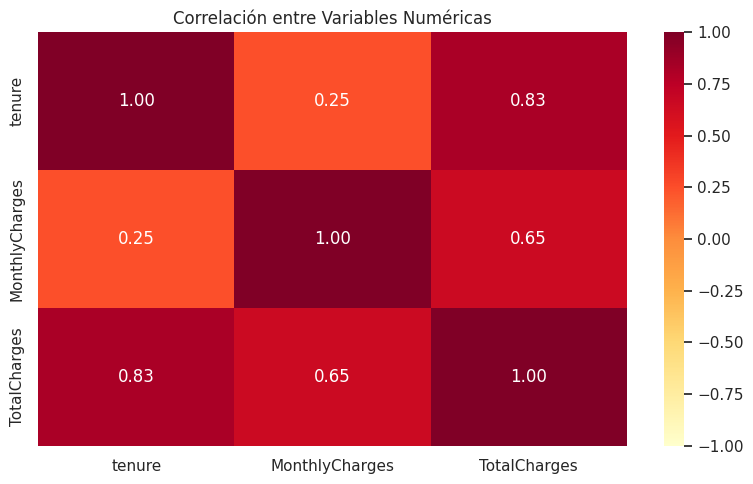

In [64]:

mostrar_titulo("\nMapa de Calor (Heatmap) - Correlación de Pearson")

# Configuración del tamaño del gráfico
plt.figure(figsize=(8, 5))

# Creación del Heatmap usando la paleta coolwarm simétrica
sns.heatmap(
    correlacion_pearson,
    annot=True,
    cmap='YlOrRd',
    vmin=-1,
    vmax=1,
    fmt='.2f'
)

# Ajustes de formato y renderizado
plt.title('Correlación entre Variables Numéricas')
plt.tight_layout()
plt.show()


*El mapa de calor muestra que la relación más fuerte se encuentra entre la antigüedad del cliente (tenure) y los cargos acumulados (TotalCharges), con una correlación de Pearson de 0,83. También se observa una relación positiva entre los cargos mensuales y los acumulados (0,65). En cambio, la relación entre la antigüedad y el cargo mensual es más débil (0,25).*

### Analisis de las variables categóricas

▶  Análisis de Frecuencias de Churn


In [65]:
# Comenzaremos con Churn, Contract y PaymentMethod, porque son especialmente útiles
# para analizar nuestra hipótesis: los clientes con contratos
# mensuales tienen una tasa de abandono mayor que aquellos con contratos de uno o dos años.


# Cálculo de frecuencias absolutas y relativas (porcentajes)
mostrar_titulo("Distribución General del Abandono (Churn)")
frecuencia_absoluta = df_clean['Churn'].value_counts()
frecuencia_relativa = df_clean['Churn'].value_counts(normalize=True) * 100

# Integración en un DataFrame homogéneo
tabla_churn = pd.DataFrame({
    'Cantidad de clientes': frecuencia_absoluta,
    'Porcentaje (%)': frecuencia_relativa
})

display(tabla_churn.round(2))


,Cantidad de clientes,Porcentaje (%)
Churn,,
no,5174,73.46
yes,1869,26.54


| Estado del cliente | Cantidad | Porcentaje |
|---|---:|---:|
| No abandonó (`no`) | 5.174 | 73,46 % |
| Abandonó (`yes`) | 1.869 | 26,54 % |
| **Total** | **7.043** | **100 %** |

*La distribución de la variable `Churn` muestra que el 73,46 % de los clientes permaneció en la empresa, mientras que el 26,54 % abandonó el servicio. Esto significa que aproximadamente uno de cada cuatro clientes dejó de ser cliente. Este porcentaje permite dimensionar el problema del abandono y justifica analizar qué características están relacionadas con una mayor tasa de churn.
Estos porcentajes representan la distribución general del abandono. Todavía no explican qué características tienen los clientes que se van; para eso, vamos a comparar los grupos.*

▶  Análisis de Frecuencias de Contratos (Contract)


In [66]:
# Frecuencia de los tipos de contrato
# cuántos clientes tienen contratos mensuales, anuales o de dos años.
# Esta variable es importante porque nuestra hipótesis plantea que los
# clientes con contratos mensuales tienen una tasa de abandono mayor que
#  los clientes con contratos de uno o dos años.

mostrar_titulo("Distribución de Clientes por Tipo de Contrato")

# Cálculo de frecuencias y proporciones
frecuencia_contrato = df_clean['Contract'].value_counts()
porcentaje_contrato = df_clean['Contract'].value_counts(normalize=True) * 100

# Consolidación en tabla limpia
tabla_contrato = pd.DataFrame({
    'Cantidad de clientes': frecuencia_contrato,
    'Porcentaje (%)': porcentaje_contrato
})

display(tabla_contrato.round(2))


,Cantidad de clientes,Porcentaje (%)
Contract,,
month-to-month,3875,55.02
two year,1695,24.07
one year,1473,20.91


▶  Cruce de Contratos vs Churn (Evaluación de Hipótesis)


In [67]:
# Nuestra hipótesis es que los clientes con contratos mensuales abandonan
# el servicio con mayor frecuencia que los clientes con contratos de uno o dos años.

# Para comprobarlo, no alcanza con saber cuántos clientes tienen cada contrato.
# Tenemos que calcular qué porcentaje de clientes abandona el servicio dentro de cada tipo de contrato.
# Creamos una tabla que cruza el tipo de contrato con el abandono

mostrar_titulo("\nVolumen de Clientes según Contrato y Abandono")

tabla_contrato_churn = pd.crosstab(df_clean['Contract'], df_clean['Churn'])
display(tabla_contrato_churn)


# evaluacion del impacto porcentual de la hipótesis
mostrar_titulo("\nTasa de Abandono Relativa por Tipo de Contrato (%)")

tasa_abandono = pd.crosstab(df_clean['Contract'], df_clean['Churn'], normalize='index') * 100
display(tasa_abandono.round(2))


Churn,no,yes
Contract,,
month-to-month,2220,1655
one year,1307,166
two year,1647,48


Churn,no,yes
Contract,,
month-to-month,57.29,42.71
one year,88.73,11.27
two year,97.17,2.83



*Al analizar el abandono según el tipo de contrato, se observa que los clientes con contratos mensuales presentan la tasa de abandono más alta, con un 42,71 %. En cambio, entre los clientes con contratos de un año, la tasa es del 11,27 %, y entre los que tienen contratos de dos años, es del 2,83 %.*

*Estos resultados respaldan nuestra hipótesis inicial: los clientes con contratos mensuales abandonan el servicio con mayor frecuencia que aquellos con contratos de mayor duración. Sin embargo, esta relación no demuestra por sí sola que el tipo de contrato sea la causa del abandono.*

▶ Cruce de Métodos de Pago (PaymentMethod) vs Churn
  

In [68]:

#  evaluacion del volumen físico por métodos de pago
mostrar_titulo("Volumen de Clientes por Método de Pago y Abandono")

tabla_pago_churn = pd.crosstab(df_clean['PaymentMethod'], df_clean['Churn'])
display(tabla_pago_churn)

# Título para evaluar el comportamiento porcentual por método de pago
mostrar_titulo("Tasa de Abandono Relativa por Método de Pago (%)")

tasa_abandono_pago = pd.crosstab(df_clean['PaymentMethod'], df_clean['Churn'], normalize='index') * 100
display(tasa_abandono_pago.round(2))




Churn,no,yes
PaymentMethod,,
bank transfer (automatic),1286,258
credit card (automatic),1290,232
electronic check,1294,1071
mailed check,1304,308


Churn,no,yes
PaymentMethod,,
bank transfer (automatic),83.29,16.71
credit card (automatic),84.76,15.24
electronic check,54.71,45.29
mailed check,80.89,19.11


| Método de pago | Tasa de abandono |
|---|---:|
| Transferencia bancaria automática | 16,71 % |
| Tarjeta de crédito automática | 15,24 % |
| Cheque electrónico | 45,29 % |
| Cheque enviado por correo | 19,11 % |

*Al analizar la tasa de abandono según el método de pago, se observa que los clientes que utilizan el cheque electrónico presentan el porcentaje más alto de abandono, con un 45,29 %. En cambio, los clientes que utilizan transferencia bancaria automática, tarjeta de crédito automática o cheque enviado por correo presentan tasas inferiores al 20 %.*

*Estos resultados muestran una asociación entre el método de pago y el abandono del servicio. Sin embargo, no permiten afirmar que el método de pago sea la causa directa del abandono.*

 ### Visualizacion


▶ Histograma y KDE de tenure

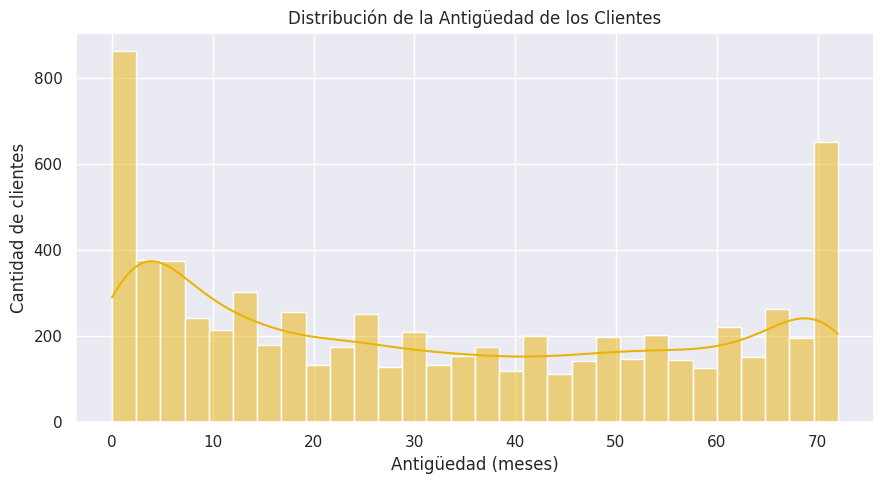

In [69]:
# Histograma y curva KDE de la antigüedad de los clientes

# el gráfico de distribución temporal
mostrar_titulo("Distribución y Densidad de la Antigüedad (Tenure)")

plt.figure(figsize=(9, 5))
sns.histplot(
    data=df_clean,
    x='tenure',
    bins=30,
    kde=True,
      color=color_primario, # <--- Usando tu variable de color azul
    edgecolor="white" # Hace que las barras se vean más prolijas
)

plt.title('Distribución de la Antigüedad de los Clientes')
plt.xlabel('Antigüedad (meses)')
plt.ylabel('Cantidad de clientes')
plt.tight_layout()
plt.show()



*El gráfico muestra que la antigüedad de los clientes presenta una distribución variable. Se observa una concentración importante de clientes nuevos, con pocos meses de antigüedad, y otro grupo numeroso de clientes que lleva cerca de 72 meses en la empresa. Entre ambos extremos, la cantidad de clientes se distribuye de manera irregular.
El gráfico muestra picos en los extremos (muchos clientes de 1 mes y muchos de 72 meses), el negocio tiene dos realidades: una masa de clientes históricos muy leales y un problema de retención temprana con clientes nuevos que se van rápido.*


▶ Histograma y KDE de MonthlyCharges (cargos mensuales)

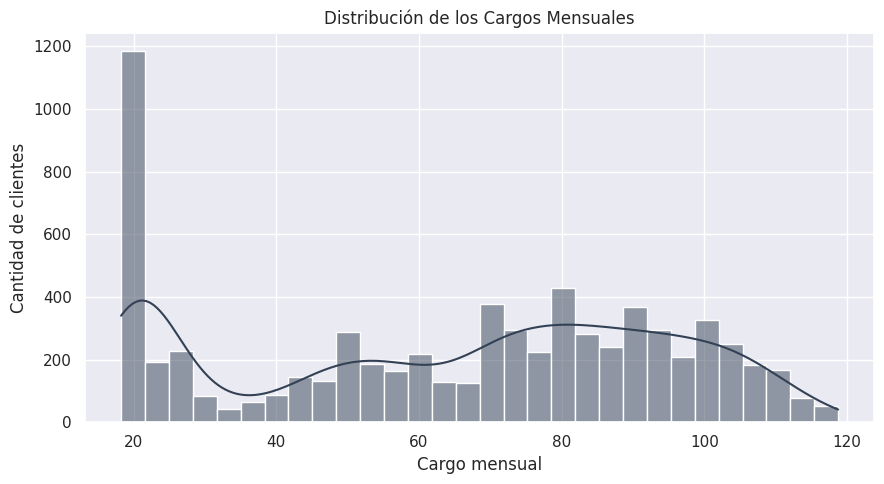

In [70]:
# Histograma y curva KDE de los cargos mensuales

#  gráfico de distribución financiera
mostrar_titulo("Distribución y Densidad de los Cargos Mensuales (MonthlyCharges)")

plt.figure(figsize=(9, 5))
sns.histplot(
    data=df_clean,
    x='MonthlyCharges',
    bins=30,
    kde=True,
    color=color_secundario, # <--- Usando tu variable de color naranja
    edgecolor="white"

)

plt.title('Distribución de los Cargos Mensuales')
plt.xlabel('Cargo mensual')
plt.ylabel('Cantidad de clientes')
plt.tight_layout()
plt.show()


*- Concentración cerca de 20: hay un pico muy marcado alrededor de los cargos mensuales más bajos, cercanos a 20. Esto indica que muchos clientes pagan importes relativamente bajos.*

*- Mayor concentración entre 70 y 100: también se observa una cantidad importante de clientes cuyos cargos mensuales se encuentran en ese rango.*

*- Menor frecuencia en algunos rangos intermedios: entre aproximadamente 25 y 40 hay menos clientes que en otros sectores del gráfico.*

*- Rango de valores: los cargos mensuales van desde aproximadamente 18 hasta 119.*

*La distribución no tiene una única concentración: presenta un pico muy marcado en los importes bajos y otra zona con bastantes clientes entre 70 y 100.*

▶ Diagramas de Barras Comparativos (Contrato y Pago vs Churn)

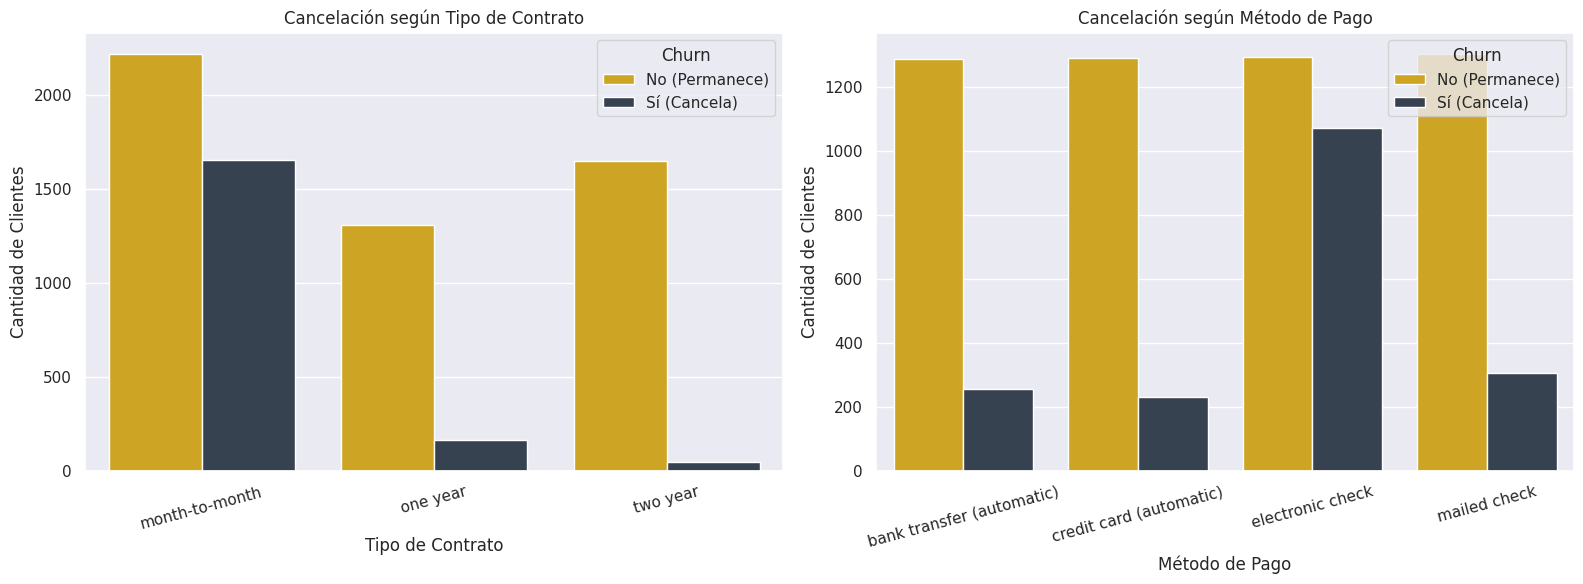

In [71]:
#  comportamiento bivariado frente al Churn
mostrar_titulo("Análisis Gráfico Bivariado Frente al Abandono (Churn)")

# Configuración del lienzo doble
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Creamos una paleta propia
# El primer color aplica a la primera categoría ('no') y el segundo a la segunda ('yes')
paleta_proyecto = [color_primario, color_secundario]

# Gráfico izquierdo: Contratos vs Churn
sns.countplot(data=df_clean, x='Contract', hue='Churn', ax=axes[0],
   palette=paleta_proyecto # <--- Aplicamos paleta personalizada
              )
axes[0].set_title('Cancelación según Tipo de Contrato')
axes[0].set_xlabel('Tipo de Contrato')
axes[0].set_ylabel('Cantidad de Clientes')
axes[0].tick_params(axis='x', rotation=15)
axes[0].legend(title='Churn', labels=['No (Permanece)', 'Sí (Cancela)'])

# Gráfico derecho: Métodos de Pago vs Churn
sns.countplot(data=df_clean, x='PaymentMethod', hue='Churn', ax=axes[1],
                palette=paleta_proyecto # <---  paleta personalizada
)
axes[1].set_title('Cancelación según Método de Pago')
axes[1].set_xlabel('Método de Pago')
axes[1].set_ylabel('Cantidad de Clientes')
axes[1].tick_params(axis='x', rotation=15)
axes[1].legend(title='Churn', labels=['No (Permanece)', 'Sí (Cancela)'])

plt.tight_layout()
plt.show()




 - *Para Tipo de Contrato: Descubrirás que el Churn masivo ocurre en los contratos Mes a Mes (Month-to-month), mientras que en los contratos a 1 y 2 años el abandono es casi nulo. Impacto en el negocio: Se debe recomendar una estrategia comercial agresiva para migrar a los clientes de contratos mensuales hacia contratos anuales (ofreciendo descuentos o beneficios), ya que el contrato mensual es el principal factor de riesgo.*

 - *Para Método de Pago: Verás que los clientes que pagan con Cheque Electrónico (Electronic check) tienen una tasa de abandono desproporcionadamente alta en comparación con los pagos automáticos (tarjeta de crédito o transferencia). Impacto en el negocio: El proceso de pago manual mediante cheque electrónico genera fricción mensual o problemas de cobranza que empujan al cliente a irse. La empresa debe incentivar activamente la domiciliación bancaria o el pago automático para asegurar la retención.*



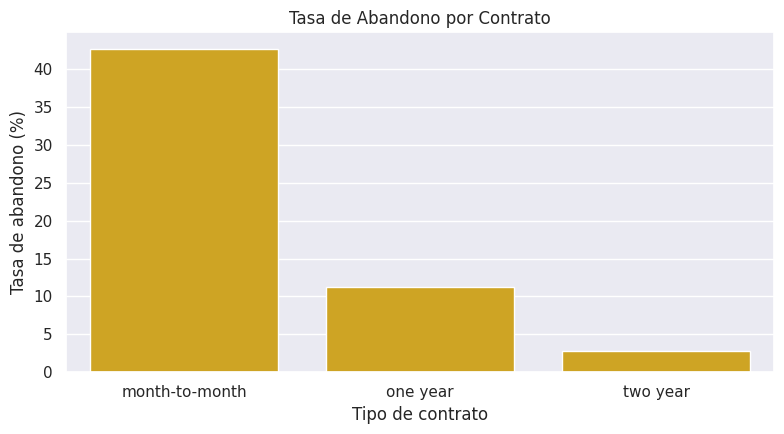

,Tasa Churn (%)
Contract,
month-to-month,42.71
one year,11.27
two year,2.83


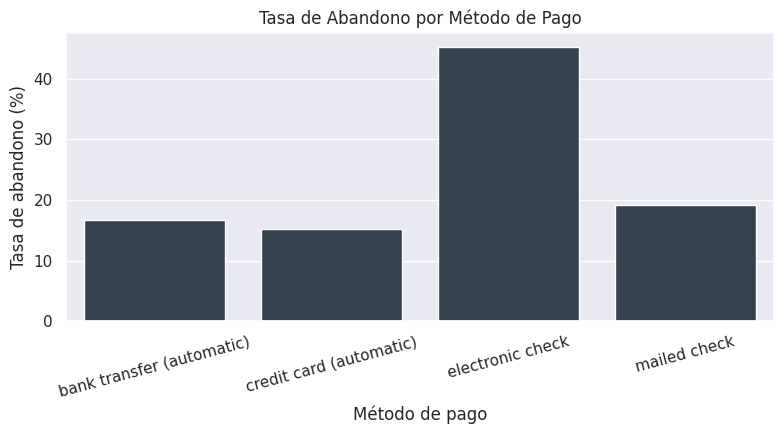

,Tasa Churn (%)
PaymentMethod,
electronic check,45.29
mailed check,19.11
bank transfer (automatic),16.71
credit card (automatic),15.24


In [72]:
# ==========================================
# TASA DE ABANDONO POR TIPO DE CONTRATO
# ==========================================

mostrar_titulo("Tasa de Abandono según el Tipo de Contrato (%)")

# Cálculo de la tasa de abandono por contrato
tasa_churn_contrato = (
    (df_clean['Churn'] == 'yes')
    .groupby(df_clean['Contract'], observed=False)
    .mean() * 100
).sort_values(ascending=False)

# Configuración del gráfico homogéneo
plt.figure(figsize=(8, 4.5))

sns.barplot(
    x=tasa_churn_contrato.index,
    y=tasa_churn_contrato.values,
    color=color_primario
)

plt.title('Tasa de Abandono por Contrato');
plt.xlabel('Tipo de contrato')
plt.ylabel('Tasa de abandono (%)')
plt.tight_layout()
plt.show()

# Mostrar la tabla de resultados redondeada
display(tasa_churn_contrato.to_frame(name='Tasa Churn (%)').round(2))

# ==========================================
#  TASA DE ABANDONO POR MÉTODO DE PAGO
# ==========================================

mostrar_titulo("Tasa de Abandono según el Método de Pago (%)")

# Cálculo de la tasa de abandono por método de pago
tasa_churn_pago = (
    (df_clean['Churn'] == 'yes')
    .groupby(df_clean['PaymentMethod'], observed=False)
    .mean() * 100
).sort_values(ascending=False)

# Configuración del gráfico homogéneo
plt.figure(figsize=(8, 4.5))

sns.barplot(
    x=tasa_churn_pago.index,
    y=tasa_churn_pago.values,
    color=color_secundario
)

# Etiquetas con rotación ligera para que no se superpongan los textos largos
plt.title('Tasa de Abandono por Método de Pago')
plt.xlabel('Método de pago')
plt.ylabel('Tasa de abandono (%)')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Mostrar la tabla de resultados redondeada
display(tasa_churn_pago.to_frame(name='Tasa Churn (%)').round(2))


 *Los contratos mes a mes (month-to-month) tienen un problema crítico de retención (~42.71%), mientras que los contratos a largo plazo (1 y 2 años) logran blindar a los clientes de forma muy efectiva.*

 *Los clientes que abonan mediante cheque electrónico (Electronic check)registran la mayor tasa de cancelación (45.29%), en comparación con las modalidades automáticas (Tarjeta de crédito y Transferencia bancaria) que mantienen tasas de Churn por debajo del 17%.*

# C. Preprocesamiento y Modelado Predictivo

## Preprocesamiento

#### ▶ Definición de las variables de entrada (X) y el objetivo (y)

In [73]:

# Mapeo de la variable objetivo categórica (binaria) Churn

mostrar_titulo("Mapeo de la variable objetivo categórica Churn");
series_churn_num=df_clean["Churn"].map({"yes": 1, "no": 0});
display(df_clean['Churn'].head(),series_churn_num.head());


# Separar las características (X) del objetivo (y)

mostrar_titulo("Separación de las caracteristicas X");
X = df_clean.drop(columns=['customerID', 'Churn'])
display(X.head())
resaltar_dato(" Dimensiones de DataFrame X (caracteristicas) ", X.shape,color=color_secundario);
resaltar_dato(" Columnas de DataFrame X ",X.columns.to_list(),color=color_secundario)


mostrar_titulo("Separación del objetivo y");
y=series_churn_num;
display(y.head())
resaltar_dato("Dimensiones de Series y (objetivo)", y.shape,color=color_terciario)
resaltar_dato("Columna de Series y ",y.name,color=color_terciario)

,Churn
0,no
1,no
2,yes
3,no
4,yes


,Churn
0,0
1,0
2,1
3,0
4,1


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,female,no,yes,no,1,no,no phone service,dsl,no,yes,no,no,no,no,month-to-month,yes,electronic check,29.85,29.85
1,male,no,no,no,34,yes,no,dsl,yes,no,yes,no,no,no,one year,no,mailed check,56.95,1889.50
2,male,no,no,no,2,yes,no,dsl,yes,yes,no,no,no,no,month-to-month,yes,mailed check,53.85,108.15
3,male,no,no,no,45,no,no phone service,dsl,yes,no,yes,yes,no,no,one year,no,bank transfer (automatic),42.30,1840.75
4,female,no,no,no,2,yes,no,fiber optic,no,no,no,no,no,no,month-to-month,yes,electronic check,70.70,151.65


,Churn
0,0
1,0
2,1
3,0
4,1


#### ▶ División de datos en entrenamiento y prueba (80/20)

In [74]:
#from sklearn.model_selection import train_test_split

# Dividir los datos en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
resaltar_dato("Datos de entrenamiento X_train",X_train.shape);
resaltar_dato("Datos de entrenamiento y_train",y_train.shape);
resaltar_dato("Datos de prueba X_test",X_test.shape,color=color_secundario);
resaltar_dato("Datos de prueba y_test",y_test.shape,color=color_secundario);


#### ▶ Identificación de columnas categóricas y numéricas

In [75]:

#### ▶ Identificación de columnas categóricas y numéricas

# 1. Definir explícitamente las variables ordinales y su orden jerárquico
columnas_ordinales = ['Contract']
orden_contrato = [['month-to-month', 'one year', 'two year']]

# 2. Identificar las columnas numéricas y categóricas nominales (excluyendo Contract)
columnas_numericas = X.select_dtypes(include=['number']).columns.tolist()
columnas_nominales = [
    col for col in X.select_dtypes(include=['category', 'object']).columns
    if col not in columnas_ordinales
]

mostrar_titulo("Columnas categóricas nominales identificadas")
resaltar_dato("Columnas nominales lista", columnas_nominales)
resaltar_dato("Cantidad de columnas nominales", len(columnas_nominales))

mostrar_titulo("Columnas categóricas ordinales identificadas")
resaltar_dato("Columnas ordinales lista", columnas_ordinales, color=color_secundario)
resaltar_dato("Orden jerárquico definido", orden_contrato[0], color=color_secundario)

mostrar_titulo("Columnas numéricas identificadas")
resaltar_dato("Columnas numéricas lista", columnas_numericas)
resaltar_dato("Cantidad de columnas numéricas", len(columnas_numericas))


#### ▶ Configuracion del preprocesador mediante ColumnTranformer


##### 🛠️ Estrategia de Preprocesamiento de Datos

| Tipo de Variable | Variables en el Dataset | Técnica / Transformación | Razón |
| :--- | :--- | :--- | :--- |
| **Categóricas Nominales** | `gender`, `Partner`, `InternetService`, `PaymentMethod`, etc. | **`OneHotEncoder`** | Convierte categorías de texto sin orden en columnas binarias (0 o 1) sin asumir jerarquía. |
| **Categórica Ordinal** | `Contract` | **`OrdinalEncoder`** | Respeta la jerarquía temporal natural del contrato (`month-to-month` = 0, `one year` = 1, `two year` = 2). |
| **Numéricas** | `tenure`, `MonthlyCharges`, `TotalCharges`, `SeniorCitizen` | **`StandardScaler`** | Sintoniza las escalas de las variables (media = 0, varianza = 1) para mejorar el rendimiento del modelo. |
| **Objetivo (Target)** | `Churn` | **Ninguna** (Mapeo Manual) | Ya fue transformada directamente a valores numéricos `0` y `1` mediante `.map()`. |



In [76]:

# Preparar las transformaciones
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

# Preparar las transformaciones (Nominales + Ordinales + Numéricas)
preprocesador = ColumnTransformer(
    transformers=[
        ('nominales', OneHotEncoder(handle_unknown='ignore',sparse_output=False), columnas_nominales),
        ('ordinales', OrdinalEncoder(categories=orden_contrato), columnas_ordinales),
        ('numericas', StandardScaler(), columnas_numericas)
    ]
)

print("Preprocesador configurado correctamente")


Preprocesador configurado correctamente


#### ▶  Apredizaje y transformación

In [77]:
#### ▶ Aprendizaje y transformación

# Guardar dimensiones antes
dimensiones_antes_train = X_train.shape
dimensiones_antes_test = X_test.shape

# Aplicar el preprocesador a los datos de entrenamiento
# .fit_transform() se aplica ÚNICAMENTE sobre el conjunto de entrenamiento (X_train)
X_train_procesado = preprocesador.fit_transform(X_train)

# .transform() se aplica sobre el conjunto de evaluación (X_test) usando lo aprendido en train
X_test_procesado = preprocesador.transform(X_test)

mostrar_titulo("Preprocesamiento de los datos de entrenamiento")
resaltar_dato("📉 ANTES del preprocesamiento (Columnas de texto y números sin escalar)", dimensiones_antes_train)
resaltar_dato("📈 DESPUES del preprocesamiento (Todo numérico: categorías codificadas y números escalados)", X_train_procesado.shape, color=color_secundario)

mostrar_titulo("Preprocesamiento de los datos de prueba")
resaltar_dato("📉 ANTES del preprocesamiento (Columnas de texto y números sin escalar)", dimensiones_antes_test)
resaltar_dato("📈 DESPUES del preprocesamiento (Todo numérico: categorías codificadas y números escalados)", X_test_procesado.shape, color=color_secundario)
print("\nPreprocesamiento completado correctamente")



Preprocesamiento completado correctamente


##### ¿Qué significa el resultado?

| Conjunto      | Antes                    | Después                  |
| ------------- | ------------------------ | ------------------------ |
| Entrenamiento | 5634 filas × 19 columnas | 5634 filas × 44 columnas |
| Prueba        | 1409 filas × 19 columnas | 1409 filas × 44 columnas |

*Las filas no cambiaron porque seguimos trabajando con los mismos clientes. Las columnas aumentaron de 19 a 44 porque **One-Hot Encoding** convirtió las 14 variables nominales en nuevas columnas binarias.*

*Por su parte, la variable ordinal **`Contract`** mantuvo una única columna numérica respetando su orden lógico (`month-to-month` = 0, `one year` = 1, `two year` = 2), sin generar columnas extra innecesarias.*

*Las variables numéricas también fueron estandarizadas mediante `StandardScaler`. Sus valores ya no están expresados directamente en meses o cargos, sino en una escala comparable con media 0 y desviación estándar 1.*


In [78]:
mostrar_titulo("Verificacion que el preprocesamiento terminó")
import numpy as np
resaltar_dato("¿Todos los valores de entrenamiento son numéricos?",np.issubdtype(X_train_procesado.dtype, np.number));
resaltar_dato("¿Hay valores faltantes en entrenamiento?",np.isnan(X_train_procesado).any());
resaltar_dato("¿Hay valores faltantes en prueba?",np.isnan(X_test_procesado).any());




## Predicción numérica

In [79]:

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

mostrar_titulo("Modelo de Regresión Lineal Simple (TotalCharges ~ tenure)")

# 1. Definir X (tenure) e y (TotalCharges) usando tu dataset limpio df_clean
X_reg = df_clean[['tenure']]
y_reg = df_clean['TotalCharges']

# 2. Partición 80/20 para regresión
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.20, random_state=42
)

# 3. Entrenamiento del modelo lineal
modelo_reg = LinearRegression()
modelo_reg.fit(X_train_reg, y_train_reg)

# 4. Predicción y Evaluación
y_pred_reg = modelo_reg.predict(X_test_reg)
r2 = r2_score(y_test_reg, y_pred_reg)
mae = mean_absolute_error(y_test_reg, y_pred_reg)


resaltar_dato("Ecuación aprendida: TotalCharges =", f"{modelo_reg.intercept_:.2f} + ({modelo_reg.coef_[0]:.2f} * tenure)")
resaltar_dato("Coeficiente de Determinación (R²)", f"{r2:.4f}", color=color_secundario)
resaltar_dato("Error Medio Absoluto (MAE)", f"${mae:.2f} USD", color=color_terciario)


*📊 Interpretación de Resultados: Regresión Lineal Simple (`TotalCharges`)*

* *Ecuación Aprendida (`TotalCharges = -196.86 + 76.73 * tenure`): El coeficiente de pendiente indica que, por cada mes adicional de permanencia (`tenure`), el gasto histórico acumulado del cliente aumenta en promedio $76.73 USD. El intercepto negativo (`-196.86`) responde únicamente al ajuste geométrico de la recta para minimizar el error en todo el rango de antigüedad, sin interpretación comercial directa en el mes cero.*

* *Coeficiente de Determinación ($R^2 = 0.6701$): La antigüedad del cliente explica por sí sola el 67.01% de la variabilidad de los cargos totales. El 32.99% restante depende de otras variables no incluidas en un modelo simple, principalmente la tarifa mensual contratada (`MonthlyCharges`).*

* *Error Medio Absoluto ($MAE = \$892.38\text{ USD}$): En promedio, las estimaciones del modelo presentan una desviación absoluta de **$892.38 USD** frente a los valores reales del conjunto de prueba.*


## Predicción categórica

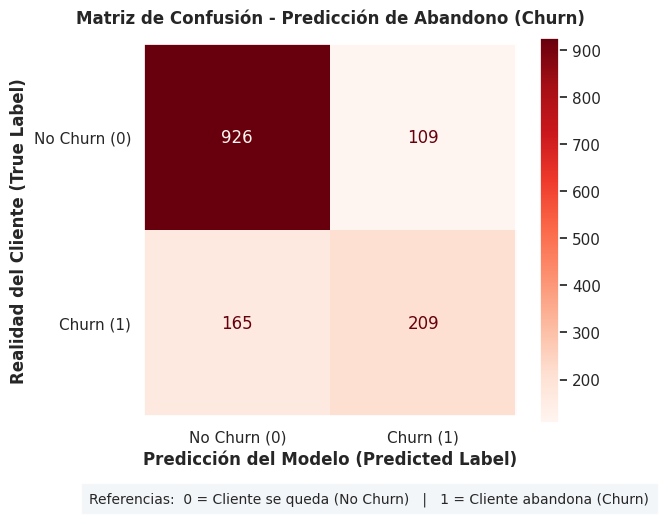

In [80]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

mostrar_titulo("Modelo de Clasificación: Regresión Logística (Churn)")

# 1. Entrenamiento usando TUS matrices ya preprocesadas
modelo_clasif = LogisticRegression(max_iter=1000, random_state=42)
modelo_clasif.fit(X_train_procesado, y_train)

# 2. Predicción sobre tus datos de prueba preprocesados
y_pred_clasif = modelo_clasif.predict(X_test_procesado)

# 3. Evaluación: Exactitud y Matriz de Confusión
accuracy = accuracy_score(y_test, y_pred_clasif)
cm = confusion_matrix(y_test, y_pred_clasif)

resaltar_dato("Exactitud del Modelo (Accuracy)", f"{accuracy * 100:.2f}%", color=color_secundario)

# 4. Gráfico de la Matriz de Confusión
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No Churn (0)', 'Churn (1)']
).plot(cmap='Reds', ax=ax, values_format='d')

# plt.title('Matriz de Confusión - Regresión Logística', fontweight='bold')

# 2. Títulos de los ejes en español
plt.title('Matriz de Confusión - Predicción de Abandono (Churn)', fontweight='bold', pad=15)
ax.set_ylabel('Realidad del Cliente (True Label)', fontweight='bold')
ax.set_xlabel('Predicción del Modelo (Predicted Label)', fontweight='bold')

# 3. Nota explicativa debajo del gráfico (actúa como leyenda)
plt.figtext(
    0.5, -0.05,
    "Referencias:  0 = Cliente se queda (No Churn)   |   1 = Cliente abandona (Churn)",
    ha="center", fontsize=10, bbox={"facecolor": "#f0f4f8", "alpha": 0.8, "pad": 6}
)

plt.grid(False)
plt.show()


*📊 Interpretación de Resultados: Modelo de Clasificación (`Churn`)*

* *Exactitud General (*Accuracy* = 80.55%): El modelo de Regresión Logística clasifica correctamente al **80.55% de los clientes** del conjunto de evaluación (datos nunca vistos durante el entrenamiento). Esto demuestra una buena capacidad predictiva general para identificar patrones de abandono.*

* *Análisis de la Matriz de Confusión:*
  * *Verdaderos Negativos (Superior Izquierda): Clientes que **no abandonan** el servicio y que el modelo predice correctamente. Representan el grueso de los aciertos.*

  * *Verdaderos Positivos (Inferior Derecha): Clientes que **efectivamente cancelan** el servicio y que el modelo logra detectar a tiempo.*

  * *Falsos Negativos (Inferior Izquierda - Error crítico de negocio): Clientes que sí abandonaron la compañía, pero que el modelo clasificó erróneamente como fieles. En estrategias de retención, este es el error más costoso, ya que representa clientes perdidos a los que no se les envió una campaña preventiva.*

  * *Falsos Positivos (Superior Derecha): Clientes fieles marcados por error como "en riesgo de abandono". Aunque implica destinar recursos promocionales innecesarios, no conlleva la pérdida directa del cliente.*
